# 01 · Data

What the data steps produced: who was in the S&P 500 on each date, which prices exist for them, and the
monthly table everything else is built on. This notebook only **reads** the outputs of the pipeline; it
doesn't download anything. To rebuild them, run the commands in the README ("Data pipeline").

> Numbers are a **preview** until the Alpha Vantage download of delisted companies is finished
> (~12–14 Nov 2026).

In [1]:
import pandas as pd

from sp500_momentum import config, eda, nb, plots

nb.setup()  # caps table output, silences info logs, applies the chart style (see sp500_momentum/nb.py)

## 1. Membership (Wikipedia)

Today's list plus the record of index changes. The record is thin before ~2008, which is why the study
starts in 2010.

In [2]:
current = pd.read_csv(config.WIKIPEDIA_DIR / "sp500_current.csv")
changes = pd.read_csv(config.WIKIPEDIA_DIR / "sp500_changes.csv", parse_dates=["date"])
decades = changes["date"].dt.year.floordiv(10).mul(10).value_counts().sort_index()
print(
    f"Current members: {len(current)}; recorded changes: {len(changes)} "
    f"({changes['date'].min():%Y} to {changes['date'].max():%Y})"
)
decades.rename("changes").rename_axis("decade").to_frame()

Current members: 503; recorded changes: 414 (1976 to 2026)


,changes
decade,
1970,2
1990,8
2000,43
2010,220
2020,141


## 2. The survivorship gap

Companies that left the index since 2010 and aren't members today, by why they left. "Missing" means
Yahoo has no usable history (none, a 1-row stub, data that starts after the removal, or a different
security that reused the ticker).

In [3]:
removed = pd.read_csv(config.REMOVED_COVERAGE)
suspects = (
    set(pd.read_csv(config.YAHOO_SUSPECT)["ticker"]) if config.YAHOO_SUSPECT.exists() else set()
)
eda.removal_gap(removed, suspects)

on_yahoo,total,on_yahoo,missing
reason_cat,,,
total,320,102,218
acquired,149,5,144
market_cap,126,81,45
spin_off,33,13,20
other,5,2,3
ticker_change,4,1,3
bankrupt_failed,3,0,3


## 3. Filling the gap: Alpha Vantage

Monthly prices for the missing companies, fetched a few each evening within the free tier's limit.

In [4]:
from sp500_momentum.dataset import _coverage_for_av
from sp500_momentum.sources import alphavantage as av

manifest = pd.read_csv(config.AV_MANIFEST)
left = len(av.build_queue(_coverage_for_av(), manifest))
print(f"Fetched so far: {len(manifest)}; still in the queue: {left}")
manifest.groupby(["reason_cat", "status"]).size().unstack(fill_value=0)

Fetched so far: 23; still in the queue: 192


status,no_data,ok
reason_cat,,
acquired,0,20
bankrupt_failed,1,2


## 4. Daily prices (Yahoo Finance) and economic data (FRED)

In [5]:
yahoo = pd.read_csv(config.YAHOO_MANIFEST, parse_dates=["first", "last"])
yahoo.groupby("group").agg(
    series=("ticker", "size"),
    daily_rows=("rows", "sum"),
    first=("first", "min"),
    last=("last", "max"),
)

,series,daily_rows,first,last
group,,,,
benchmark,16,99024,2000-01-03,2026-11-02
current,503,2955689,2000-01-03,2026-11-02
removed,108,615138,2000-01-03,2026-11-02


In [6]:
fred = {
    sid: pd.read_csv(config.FRED_DIR / f"{sid}.csv", parse_dates=["date"])
    for sid in config.FRED_SERIES
}
pd.DataFrame(
    {
        sid: {
            "name": config.FRED_SERIES[sid]["name"],
            "rows": len(d),
            "first": d["date"].min().date(),
            "last": d["date"].max().date(),
            "used after (months)": config.FRED_SERIES[sid]["lag_months"],
        }
        for sid, d in fred.items()
    }
).T

,name,rows,first,last,used after (months)
CPILFESL,"Core CPI (index, monthly)",260,2005-01-01,2026-09-01,1
FEDFUNDS,Fed Funds rate (monthly average),262,2005-01-01,2026-10-01,1
DGS1,1-year Treasury yield (daily),5462,2005-01-03,2026-10-30,0
DGS5,5-year Treasury yield (daily),5462,2005-01-03,2026-10-30,0
DGS10,10-year Treasury yield (daily),5462,2005-01-03,2026-10-30,0
GDPPOT,"Real potential GDP, CBO (quarterly)",128,2005-01-01,2036-10-01,0


## 5. The monthly table

One row per member per month-end. Members per month should sit just above 500 (a few companies have two
share classes).

In [7]:
panel = pd.read_parquet(config.MONTHLY_PANEL)
per_month = panel.groupby("date").size()
print(
    f"Rows: {len(panel):,}; month-ends: {panel['date'].nunique()} "
    f"({panel['date'].min():%b %Y} to {panel['date'].max():%b %Y}); "
    f"members per month-end: {per_month.min()}–{per_month.max()}; with a price: {panel['has_price'].mean():.1%}"
)
cov_year = eda.coverage_by_year(pd.read_csv(config.MONTHLY_COVERAGE))
cov_year

Rows: 101,431; month-ends: 202 (Jan 2010 to Oct 2026); members per month-end: 499–504; with a price: 87.4%


,members,priced_share,from_alphavantage
year,,,
2010,500.0000,0.6960,11.0000
2011,499.0000,0.7100,11.0000
2012,499.0000,0.7340,11.0000
2013,499.0000,0.7600,11.5000
2014,500.0000,0.7780,12.0000
2015,502.0000,0.7980,12.4000
2016,504.0000,0.8370,13.8000
2017,504.0000,0.8680,14.6000
2018,504.0000,0.8940,17.1000


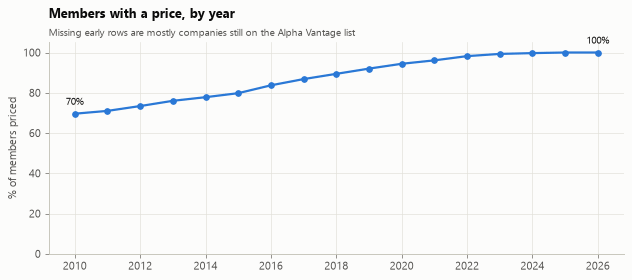

In [8]:
fig = plots.coverage_chart(cov_year)
plots.save(fig, "coverage_by_year")

## 6. The feature table

Every column belongs to exactly one named set; the build checks it.

In [9]:
from sp500_momentum.features import feature_sets

feats = pd.read_parquet(config.FEATURES_TABLE)
sets = feature_sets(feats.columns)
priced = feats[feats["has_price"]]
pd.DataFrame(
    {
        name: {"columns": len(cols), "filled (priced rows)": priced[cols].notna().mean().mean()}
        for name, cols in sets.items()
    }
).T

,columns,filled (priced rows)
INFO,10.0000,0.9968
TO_PREDICT,24.0000,0.9740
PAST_RETURNS,5.0000,0.9978
TA,52.0000,0.9915
STOCK,22.0000,0.9950
CROSS_SECTION,17.0000,0.9970
MARKET,24.0000,1.0000
MACRO,9.0000,1.0000
DUMMIES,23.0000,1.0000
